# Redes neuronales convolucionales sobre ecografías reales
### Fetal Medical Bolivia · Proyecto Integrador 2026 · UNIFRANZ

Dos modelos de aprendizaje **supervisado**, entrenados con **ecografías reales**
en las que **cada imagen viene con su información** medida por profesionales:

| Modelo | Tipo | Qué aprende | Dataset real |
|---|---|---|---|
| **1. Circunferencia cefálica** | Regresión | De la imagen de la cabeza, cuántos **milímetros** mide su contorno | **HC18** · 999 imágenes de 779 madres (Países Bajos) |
| **2. Plano anatómico** | Clasificación | De la imagen, qué **parte del cuerpo** muestra | **FETAL_PLANES_DB** · 12.400 imágenes de 1.792 madres (Barcelona) |

Las imágenes están en `imagenes/` y la información de cada una en
`catalogo_imagenes.xlsx` (una fila por imagen).

| Sección | Contenido |
|---|---|
| **Antes de empezar** | Qué es Hadlock y qué tiene que ver con estas imágenes |
| Paso 1 | Importación de librerías |
| Paso 2 | Carga de datos: imágenes + información |
| Paso 3 | Exploración de datos |
| Paso 4 | Definición de variables de entrada (X) y objetivo (y) |
| Paso 5 | Crear y entrenar las redes |
| Paso 6 | Hacer predicciones |
| Paso 7 | Evaluar: R², curvas ROC de verdaderos positivos, matrices de confusión, y cómo implementarlo |

---
## Antes de empezar: ¿qué es Hadlock?

**Frank P. Hadlock** fue un radiólogo estadounidense que, en los años 80,
publicó con su equipo las fórmulas que se usan en todo el mundo para
interpretar las medidas de una ecografía fetal. Dos de ellas importan aquí:

**1. De la cabeza a la edad del embarazo (Hadlock 1984).** La circunferencia
cefálica (el contorno de la cabeza) crece de forma muy regular. Midiéndola se
sabe cuántas semanas tiene el embarazo:

$$\text{semanas} = 8{,}96 + 0{,}540 \cdot CC + 0{,}0003 \cdot CC^3 \qquad (CC \text{ en centímetros})$$

**2. De las medidas al peso (Hadlock 1985).** Con la cabeza, el abdomen y el
fémur se estima cuánto pesa el bebé. Es la fórmula que usa el sistema y en la
que encontramos el error de unidades (devolvía 0 g en el 62% de los casos).

**Qué tiene que ver con este notebook.** Todas las fórmulas de Hadlock
necesitan que **alguien mida primero** la cabeza en la pantalla del ecógrafo.
La red del modelo 1 hace esa medida **sola, a partir de la imagen**. Y el modelo
2 comprueba antes que la imagen sea de verdad una cabeza, porque medir el
contorno de un fémur como si fuera una cabeza daría una edad sin sentido.

```
imagen ──► ¿qué plano es? (modelo 2) ──► si es cabeza ──► ¿cuánto mide? (modelo 1) ──► Hadlock ──► semanas
```

In [1]:
def semanas_por_hc(hc_mm):
    # Hadlock 1984. Recibe milímetros; la fórmula está en centímetros.
    cc = hc_mm / 10
    return 8.96 + 0.540 * cc + 0.0003 * cc ** 3

for hc in (100, 175, 250, 330):
    print(f"Circunferencia cefálica {hc} mm  ->  {semanas_por_hc(hc):4.1f} semanas de embarazo")

Circunferencia cefálica 100 mm  ->  14.7 semanas de embarazo
Circunferencia cefálica 175 mm  ->  20.0 semanas de embarazo
Circunferencia cefálica 250 mm  ->  27.1 semanas de embarazo
Circunferencia cefálica 330 mm  ->  37.6 semanas de embarazo


---
## Paso 1: Importación de librerías

Además de **pandas**, **numpy**, **matplotlib** y **scikit-learn**, aquí hacen
falta **PyTorch** (las redes neuronales) y **timm** (la red EfficientNet-B0
ya preentrenada). Se entrena en la tarjeta gráfica (GPU), que lo hace unas 50
veces más rápido que el procesador.

In [2]:
# Paso 1: Importación de librerías
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import timm
from sklearn.metrics import (mean_absolute_error, r2_score, roc_curve, roc_auc_score,
                             confusion_matrix, accuracy_score)

import cnn_ecografia as cnn   # el código de las dos redes, en esta misma carpeta

warnings.filterwarnings("ignore")
AZUL, OCRE, ROJO, VERDE, GRIS = "#2e5b86", "#9a7327", "#a8412f", "#2b7656", "#9aa4a8"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})

print(f"PyTorch {torch.__version__} · timm {timm.__version__}")
print(f"GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NO (irá lento)'}")

C:\Users\Miscar\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\cuda\__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


PyTorch 2.6.0+cu124 · timm 1.0.27
GPU: NVIDIA GeForce RTX 3090


---
## Paso 2: Carga de datos: imágenes + información

`catalogo_imagenes.xlsx` tiene una fila por imagen. Cada fila dice **dónde está
la imagen** (columna `ruta`) y **toda su información**. Hojas:

| Hoja | Contenido |
|---|---|
| **HC18** | 999 filas: paciente, tamaño del píxel, circunferencia medida, edad gestacional, partición |
| **Planos** | 12.400 filas: paciente, plano, subplano, operador, ecógrafo, partición |
| **Diccionario** | Qué significa cada columna |
| **Fuentes** | Publicaciones, licencias, y qué datasets se descartaron y por qué |

In [3]:
# Paso 2: Carga de datos
CATALOGO = Path("catalogo_imagenes.xlsx")
hc = pd.read_excel(CATALOGO, sheet_name="HC18")
planos = pd.read_excel(CATALOGO, sheet_name="Planos")
fuentes = pd.read_excel(CATALOGO, sheet_name="Fuentes")

print(f"HC18:   {len(hc):>6,} imágenes · {hc['paciente'].nunique():,} madres".replace(",", "."))
print(f"Planos: {len(planos):>6,} imágenes · {planos['paciente'].nunique():,} madres".replace(",", "."))
hc.head(6)

HC18:      999 imágenes · 779 madres
Planos: 12.400 imágenes · 1.792 madres


,archivo,ruta,paciente,imagen_de_la_paciente,tamano_pixel_mm,circunferencia_cefalica_mm,edad_gestacional_hadlock_sem,trimestre,particion
0,1_HC.png,imagenes/hc18/1_HC.png,HC18-P0001,1,0.069136,44.30,11.4,primero,validacion
1,2_HC.png,imagenes/hc18/2_HC.png,HC18-P0002,1,0.089659,56.81,12.1,primero,prueba
2,3_HC.png,imagenes/hc18/3_HC.png,HC18-P0003,1,0.062033,68.75,12.8,primero,entrenamiento
3,4_HC.png,imagenes/hc18/4_HC.png,HC18-P0004,1,0.091291,69.00,12.8,primero,entrenamiento
4,5_HC.png,imagenes/hc18/5_HC.png,HC18-P0005,1,0.061240,59.81,12.3,primero,prueba
5,6_HC.png,imagenes/hc18/6_HC.png,HC18-P0006,1,0.115814,69.80,12.8,primero,validacion


In [4]:
planos.head(6)

,archivo,ruta,paciente,plano,plano_original,subplano_cerebral,operador,ecografo,particion_oficial,particion
0,Patient00001_Plane1_1_of_15.png,imagenes/planos_fetales/Patient00001_Plane1_1_...,FP-P00001,otro,Other,Not A Brain,Other,Aloka,entrenamiento,entrenamiento
1,Patient00001_Plane1_2_of_15.png,imagenes/planos_fetales/Patient00001_Plane1_2_...,FP-P00001,otro,Other,Not A Brain,Other,Aloka,entrenamiento,entrenamiento
2,Patient00001_Plane1_3_of_15.png,imagenes/planos_fetales/Patient00001_Plane1_3_...,FP-P00001,otro,Other,Not A Brain,Other,Aloka,entrenamiento,entrenamiento
3,Patient00001_Plane1_4_of_15.png,imagenes/planos_fetales/Patient00001_Plane1_4_...,FP-P00001,otro,Other,Not A Brain,Other,Aloka,entrenamiento,entrenamiento
4,Patient00001_Plane1_5_of_15.png,imagenes/planos_fetales/Patient00001_Plane1_5_...,FP-P00001,otro,Other,Not A Brain,Other,Aloka,entrenamiento,entrenamiento
5,Patient00001_Plane1_6_of_15.png,imagenes/planos_fetales/Patient00001_Plane1_6_...,FP-P00001,otro,Other,Not A Brain,Other,Aloka,entrenamiento,entrenamiento


**De dónde vienen, y qué se descartó:**

In [5]:
pd.set_option("display.max_colwidth", 110)
fuentes

,dataset,estado,motivo,cita_y_licencia
0,HC18,USADO,999 imágenes de cabeza fetal con la circunferencia medida por ecografista,van den Heuvel TLA et al. PLoS ONE 2018;13(8):e0200412 · Zenodo 1327317 · CC BY 4.0
1,FETAL_PLANES_DB,USADO,12.400 imágenes de 6 planos anatómicos de 1.792 pacientes,Burgos-Artizzu XP et al. Sci Rep 2020;10:10200 · Zenodo 3904280 · CC BY 4.0
2,Large-Scale Fetal Head Biometry,NO USADO,Solo máscaras de segmentación; la medida habría que calcularla nosotros,CC BY 4.0
3,Fetal Brain Abnormalities (Roboflow),NO USADO,Trae varias copias aumentadas de la misma imagen: se colarían entre entrenamiento y prueba,Roboflow
4,Fetal Abdominal Structures,NO USADO,"Solo máscaras de segmentación, sin información numérica",—
5,fetal-ultrasound-brain,NO USADO,Es un subconjunto de FETAL_PLANES_DB (solo planos cerebrales),Kaggle
6,IUGC MICCAI 2024,NO USADO,Ecografía durante el parto: otro problema clínico,MICCAI 2024
7,Fetal Health Classification,NO USADO,"Solo tabla de cardiotocografía, sin imágenes",UCI / Kaggle
8,Agrupación por paciente en HC18,NOTA,"15_HC, 16_2HC, 17_3HC = 1.ª, 2.ª y 3.ª imagen de la misma madre; cada imagen se agrupa con el último _HC a...",—


**Imagen + información, caso por caso.** Así se ve cada fila del catálogo con
su imagen:

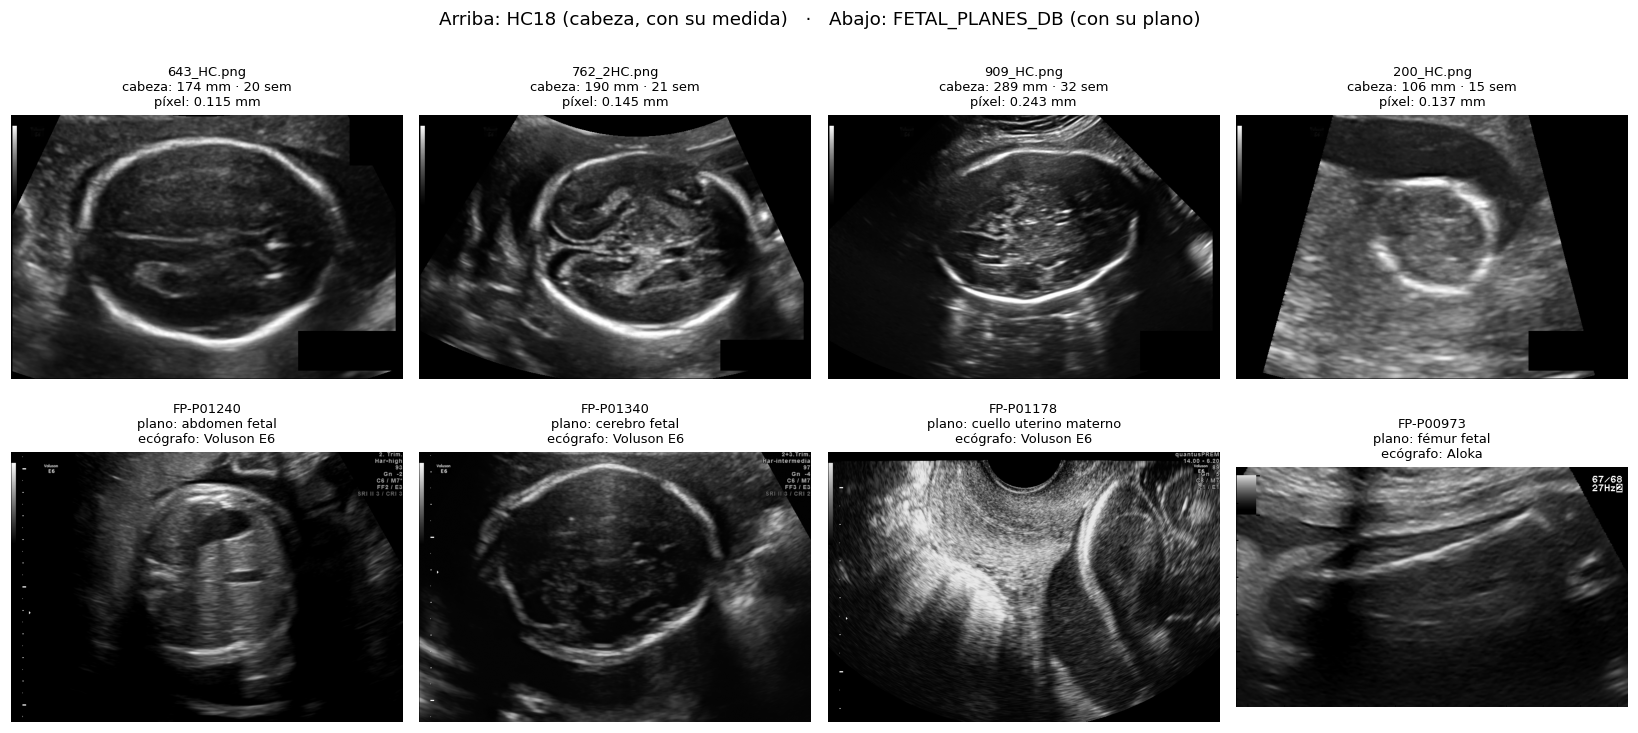

In [6]:
fig, ejes = plt.subplots(2, 4, figsize=(15, 7))
for ax, (_, f) in zip(ejes[0], hc.sample(4, random_state=3).iterrows()):
    ax.imshow(Image.open(f["ruta"]), cmap="gray"); ax.axis("off")
    ax.set_title(f"{f['archivo']}\ncabeza: {f['circunferencia_cefalica_mm']:.0f} mm · "
                 f"{f['edad_gestacional_hadlock_sem']:.0f} sem\npíxel: {f['tamano_pixel_mm']:.3f} mm",
                 fontsize=8.5)
for ax, (_, f) in zip(ejes[1], planos.groupby("plano").sample(1, random_state=2).head(4).iterrows()):
    ax.imshow(Image.open(f["ruta"]), cmap="gray"); ax.axis("off")
    ax.set_title(f"{f['paciente']}\nplano: {f['plano']}\necógrafo: {f['ecografo']}", fontsize=8.5)
fig.suptitle("Arriba: HC18 (cabeza, con su medida)   ·   Abajo: FETAL_PLANES_DB (con su plano)", y=1.0)
plt.tight_layout()
plt.show()

---
## Paso 3: Exploración de datos

### 3.1 HC18: cómo se reparten las medidas

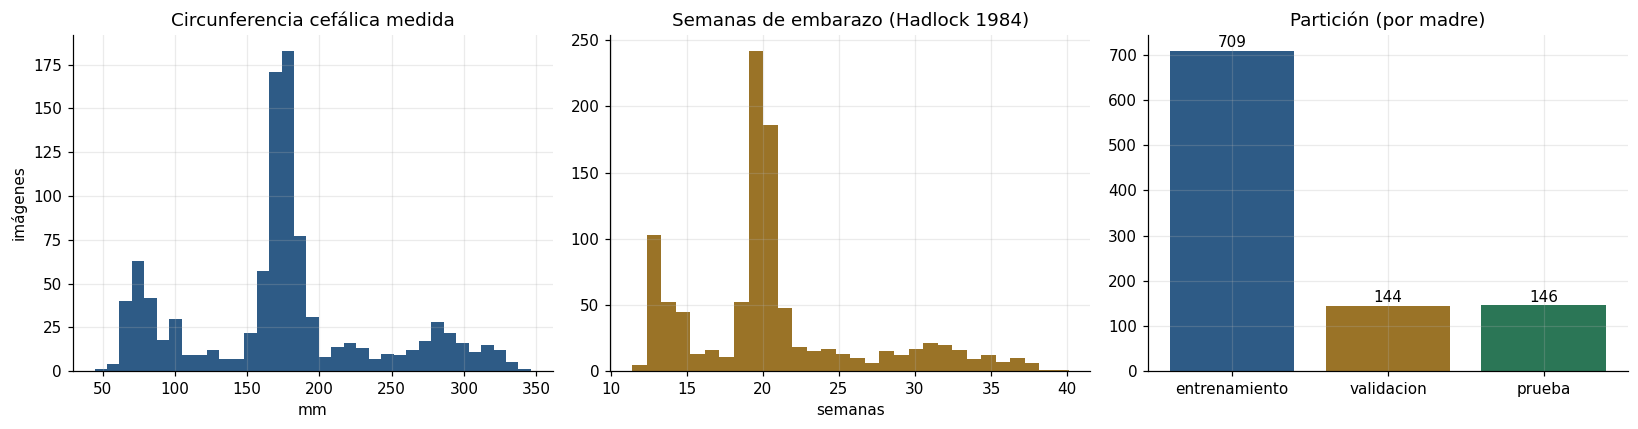

           count     min  median     max
trimestre                               
primero      153   44.30   75.30   88.51
segundo      701   88.81  174.15  255.80
tercero      145  257.60  289.50  346.40


In [7]:
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(15, 4))
a1.hist(hc["circunferencia_cefalica_mm"], bins=35, color=AZUL)
a1.set_title("Circunferencia cefálica medida"); a1.set_xlabel("mm"); a1.set_ylabel("imágenes")
a2.hist(hc["edad_gestacional_hadlock_sem"], bins=30, color=OCRE)
a2.set_title("Semanas de embarazo (Hadlock 1984)"); a2.set_xlabel("semanas")
cuenta = hc["particion"].value_counts().reindex(["entrenamiento", "validacion", "prueba"])
a3.bar(cuenta.index, cuenta.values, color=[AZUL, OCRE, VERDE])
for i, v in enumerate(cuenta.values):
    a3.text(i, v + 8, str(v), ha="center")
a3.set_title("Partición (por madre)")
plt.tight_layout()
plt.show()
print(hc.groupby("trimestre")["circunferencia_cefalica_mm"].agg(["count", "min", "median", "max"]))

Las cabezas van de **44 mm a 346 mm**: desde el primer trimestre hasta el
final del embarazo. Una misma red tiene que medir las dos cosas.

### 3.2 Planos: cuántas imágenes de cada tipo

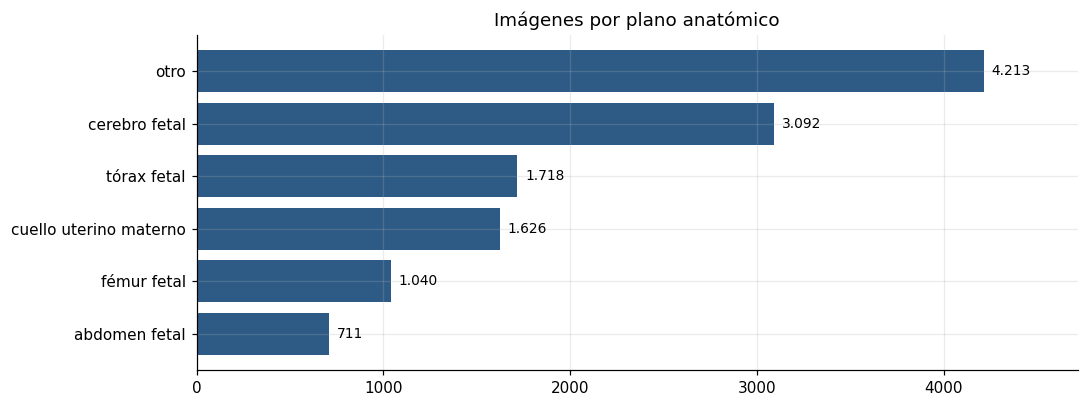

particion,entrenamiento,validacion,prueba,total
plano,,,,
abdomen fetal,331,22,358,711
fémur fetal,487,29,524,1040
cuello uterino materno,866,115,645,1626
tórax fetal,951,107,660,1718
cerebro fetal,1475,145,1472,3092
otro,2361,240,1612,4213


In [8]:
tabla = pd.crosstab(planos["plano"], planos["particion"])[["entrenamiento", "validacion", "prueba"]]
tabla["total"] = tabla.sum(axis=1)
tabla = tabla.sort_values("total")
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(tabla.index, tabla["total"], color=AZUL)
for i, v in enumerate(tabla["total"]):
    ax.text(v + 40, i, f"{v:,}".replace(",", "."), va="center", fontsize=9)
ax.set_title("Imágenes por plano anatómico")
ax.set_xlim(0, tabla["total"].max() * 1.12)
plt.tight_layout()
plt.show()
tabla

**Las clases no están equilibradas**: hay seis veces más imágenes de «otro»
que de «abdomen». En el paso 5 se compensa para que la red no aprenda a decir
«otro» ante la duda.

### 3.3 ¿Hay madres repetidas entre entrenamiento y prueba?

In [9]:
for nombre, d in [("HC18", hc), ("Planos", planos)]:
    ent = set(d.loc[d["particion"] == "entrenamiento", "paciente"])
    pru = set(d.loc[d["particion"] == "prueba", "paciente"])
    print(f"{nombre:<7} madres en entrenamiento Y en prueba: {len(ent & pru)}")

HC18    madres en entrenamiento Y en prueba: 0
Planos  madres en entrenamiento Y en prueba: 0


**Cero, en los dos.** Es la comprobación más importante del notebook: si una
misma madre estuviera en los dos lados, la red la «reconocería» y los
resultados saldrían inflados.

---
## Paso 4: Definición de variables de entrada (X) y objetivo (y)

| | Modelo 1: circunferencia | Modelo 2: plano |
|---|---|---|
| **X (entrada)** | La imagen **+ el tamaño del píxel** | La imagen |
| **y (objetivo)** | `circunferencia_cefalica_mm` | `plano` (6 clases) |

**Por qué el modelo 1 necesita el tamaño del píxel.** La red ve píxeles, y no
puede saber cuántos milímetros mide cada uno: depende del zoom del ecógrafo.
Una cabeza de 100 mm con mucho zoom ocupa lo mismo que una de 300 mm sin zoom.
Así que la red aprende **qué parte de la imagen ocupa el contorno de la cabeza**,
y los milímetros se sacan multiplicando por el tamaño del píxel. **Es la unión
de imagen e información**: sin ese dato, la misma imagen no tiene medida.

Las imágenes se **rellenan hasta hacerlas cuadradas sin deformarlas** antes de
reducirlas. Estirarlas achataría la cabeza y cambiaría su contorno.

In [10]:
# Paso 4: Definición de variables de entrada (X) y objetivo (y)
ejemplo = hc.iloc[0]
img, lado_mayor = cnn.cargar_cuadrada(Path(ejemplo["ruta"]), cnn.LADO_HC)
fraccion = ejemplo["circunferencia_cefalica_mm"] / (ejemplo["tamano_pixel_mm"] * lado_mayor)

print(f"Imagen original: lado mayor {lado_mayor} píxeles · píxel de {ejemplo['tamano_pixel_mm']:.4f} mm")
print(f"X = imagen de {img.shape[0]}×{img.shape[1]} píxeles en gris")
print(f"y = {ejemplo['circunferencia_cefalica_mm']} mm  ->  lo que aprende la red: "
      f"el contorno mide {fraccion:.3f} veces el lado de la imagen")
print(f"De vuelta a mm: {fraccion:.3f} × {lado_mayor} px × {ejemplo['tamano_pixel_mm']:.4f} mm = "
      f"{fraccion * lado_mayor * ejemplo['tamano_pixel_mm']:.2f} mm")

Imagen original: lado mayor 800 píxeles · píxel de 0.0691 mm
X = imagen de 320×320 píxeles en gris
y = 44.3 mm  ->  lo que aprende la red: el contorno mide 0.801 veces el lado de la imagen
De vuelta a mm: 0.801 × 800 px × 0.0691 mm = 44.30 mm


---
## Paso 5: Crear y entrenar las redes

Las dos redes parten de **EfficientNet-B0 preentrenada**: una red que ya sabe
reconocer bordes, texturas y formas en millones de fotografías, y a la que
solo hay que enseñarle ecografía. Con pocos cientos de imágenes, empezar de
cero no funcionaría.

Durante el entrenamiento, cada imagen se **voltea, gira y cambia de brillo al
azar**: así la red aprende la forma de la cabeza y no una imagen concreta. Al
final de cada época se mide el error en **validación**, y **se guarda la época
que mejor va en validación**, nunca en prueba: elegir con la prueba sería mirar
las respuestas del examen.

### 5.1 Red 1: circunferencia cefálica (regresión)

In [11]:
# Paso 5: Crear y entrenar las redes
t = time.time()
red_hc, historia_hc, prueba_hc = cnn.entrenar_circunferencia(hc, epocas=40)
print(f"\nEntrenada en {time.time() - t:.0f} segundos")

  entrenamiento  709 imágenes
  validacion     144 imágenes


  prueba         146 imágenes


  época  1/40  pérdida 3.3987  validación 3.7054  (3 s)


  época  2/40  pérdida 2.9447  validación 3.8410  (2 s)


  época  3/40  pérdida 2.7462  validación 2.3625  (2 s)


  época  4/40  pérdida 2.6897  validación 3.5663  (2 s)


... (32 outputs left out)

  época 37/40  pérdida 0.0446  validación 0.0749  (2 s)


  época 38/40  pérdida 0.0379  validación 0.0632  (2 s)


  época 39/40  pérdida 0.0431  validación 0.0766  (2 s)


  época 40/40  pérdida 0.0473  validación 0.0975  (2 s)

Entrenada en 87 segundos


### 5.2 Red 2: plano anatómico (clasificación)

In [12]:
t = time.time()
red_planos, historia_planos, prueba_planos = cnn.entrenar_planos(planos, epocas=14)
print(f"\nEntrenada en {time.time() - t:.0f} segundos")

  entrenamiento  6471 imágenes


  validacion      658 imágenes


  prueba         5271 imágenes


  época  1/14  pérdida 1.7420  validación 0.8342  (9 s)


  época  2/14  pérdida 0.6379  validación 0.4012  (9 s)


  época  3/14  pérdida 0.4912  validación 0.2348  (9 s)


... (8 outputs left out)

  época 12/14  pérdida 0.3263  validación 0.1930  (9 s)


  época 13/14  pérdida 0.3192  validación 0.2145  (9 s)


  época 14/14  pérdida 0.3212  validación 0.1969  (9 s)



Entrenada en 140 segundos


### 5.3 Cómo aprendieron

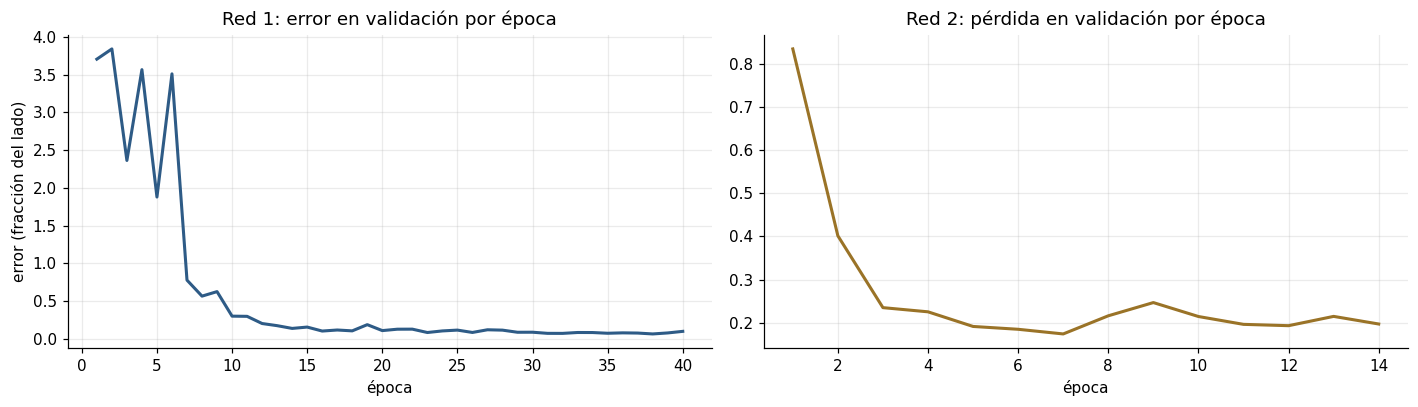

In [13]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.8))
h = pd.DataFrame(historia_hc)
a1.plot(h["epoca"], h["val"], color=AZUL, lw=2)
a1.set_title("Red 1: error en validación por época"); a1.set_xlabel("época")
a1.set_ylabel("error (fracción del lado)")
h = pd.DataFrame(historia_planos)
a2.plot(h["epoca"], h["val"], color=OCRE, lw=2)
a2.set_title("Red 2: pérdida en validación por época"); a2.set_xlabel("época")
plt.tight_layout()
plt.show()

In [14]:
# Guardar las dos redes con lo necesario para usarlas igual en el sistema
ruta_hc = cnn.guardar(red_hc, "circunferencia_cefalica_hc18", {
    "arquitectura": "efficientnet_b0", "lado": cnn.LADO_HC, "media": cnn.MEDIA, "desv": cnn.DESV,
    "salida": "fraccion del lado mayor de la imagen; mm = fraccion * lado_mayor_px * tamano_pixel_mm",
    "dataset": "HC18 (Zenodo 1327317, CC BY 4.0)", "entrenamiento": len(hc[hc.particion == "entrenamiento"]),
})
ruta_planos = cnn.guardar(red_planos, "plano_anatomico_fetal_planes", {
    "arquitectura": "efficientnet_b0", "lado": cnn.LADO_PLANO, "media": cnn.MEDIA, "desv": cnn.DESV,
    "clases": cnn.PLANOS, "dataset": "FETAL_PLANES_DB (Zenodo 3904280, CC BY 4.0)",
})
print("Guardadas:", ruta_hc.name, "·", ruta_planos.name)

Guardadas: circunferencia_cefalica_hc18.pth · plano_anatomico_fetal_planes.pth


---
## Paso 6: Hacer predicciones

Las dos redes se aplican a imágenes de **prueba**: madres que no vieron nunca.

### 6.1 Red 1: la medida de la cabeza, imagen por imagen

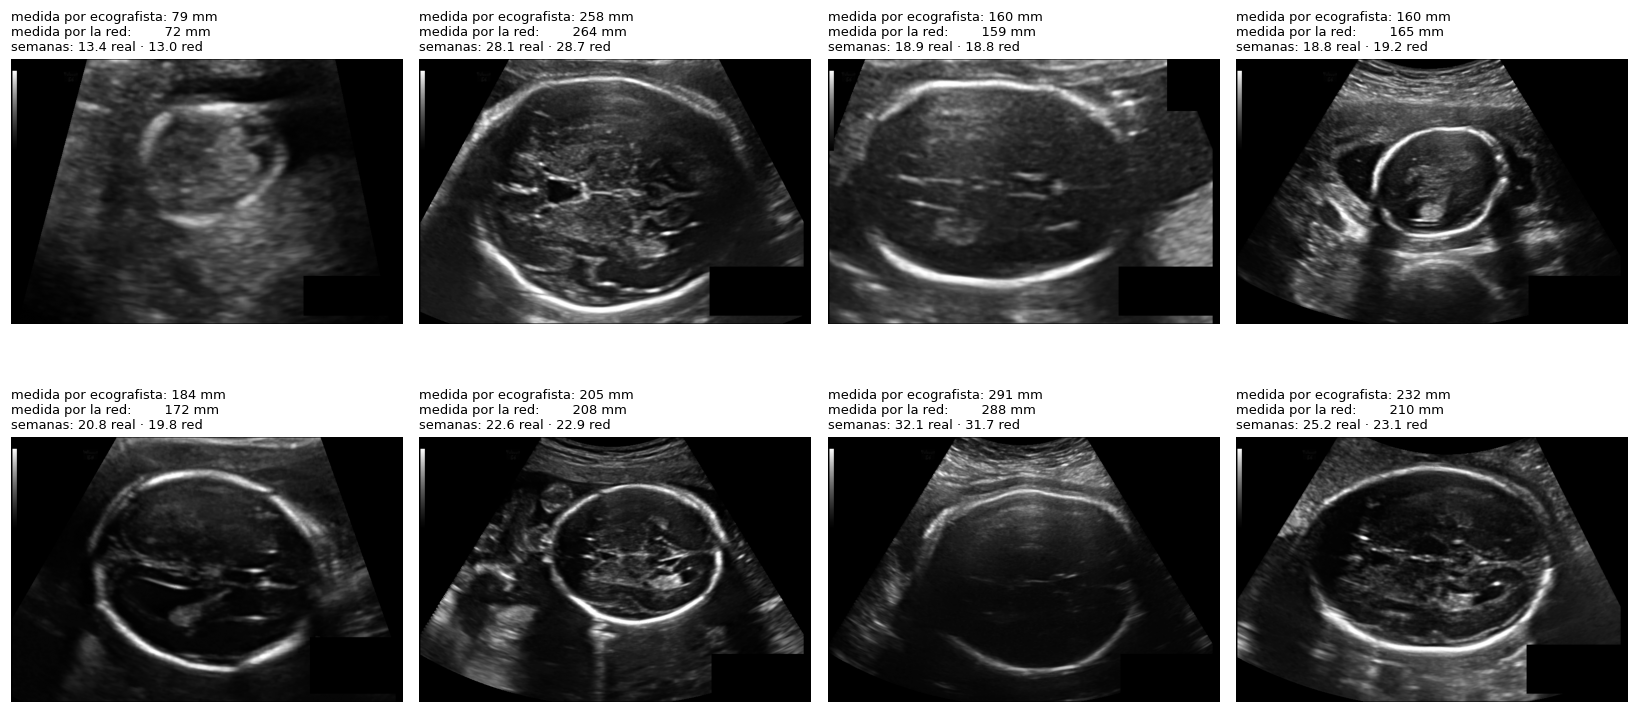

In [15]:
# Paso 6: Hacer predicciones
prueba_hc["semanas_real"] = semanas_por_hc(prueba_hc["circunferencia_cefalica_mm"]).round(1)
prueba_hc["semanas_predichas"] = semanas_por_hc(prueba_hc["hc_predicha_mm"]).round(1)

fig, ejes = plt.subplots(2, 4, figsize=(15, 7.5))
for ax, (_, f) in zip(ejes.ravel(), prueba_hc.sample(8, random_state=7).iterrows()):
    ax.imshow(Image.open(f["ruta"]), cmap="gray"); ax.axis("off")
    ax.set_title(f"medida por ecografista: {f['circunferencia_cefalica_mm']:.0f} mm\n"
                 f"medida por la red:        {f['hc_predicha_mm']:.0f} mm\n"
                 f"semanas: {f['semanas_real']:.1f} real · {f['semanas_predichas']:.1f} red",
                 fontsize=8.5, loc="left")
plt.tight_layout()
plt.show()

In [16]:
prueba_hc[["archivo", "circunferencia_cefalica_mm", "hc_predicha_mm", "error_mm",
           "semanas_real", "semanas_predichas"]].head(12)

,archivo,circunferencia_cefalica_mm,hc_predicha_mm,error_mm,semanas_real,semanas_predichas
0,2_HC.png,56.81,57.16,0.35,12.1,12.1
1,5_HC.png,59.81,60.24,0.43,12.3,12.3
2,7_HC.png,67.84,73.45,5.61,12.7,13.0
3,8_2HC.png,62.80,74.76,11.96,12.4,13.1
4,33_HC.png,70.51,67.73,-2.78,12.9,12.7
5,34_2HC.png,75.20,63.85,-11.35,13.1,12.5
6,51_HC.png,68.70,79.34,10.64,12.8,13.4
7,53_HC.png,69.84,65.27,-4.57,12.8,12.6
8,64_HC.png,71.91,76.10,4.19,13.0,13.2
9,91_HC.png,76.29,70.26,-6.03,13.2,12.9


### 6.2 Red 2: el plano, imagen por imagen

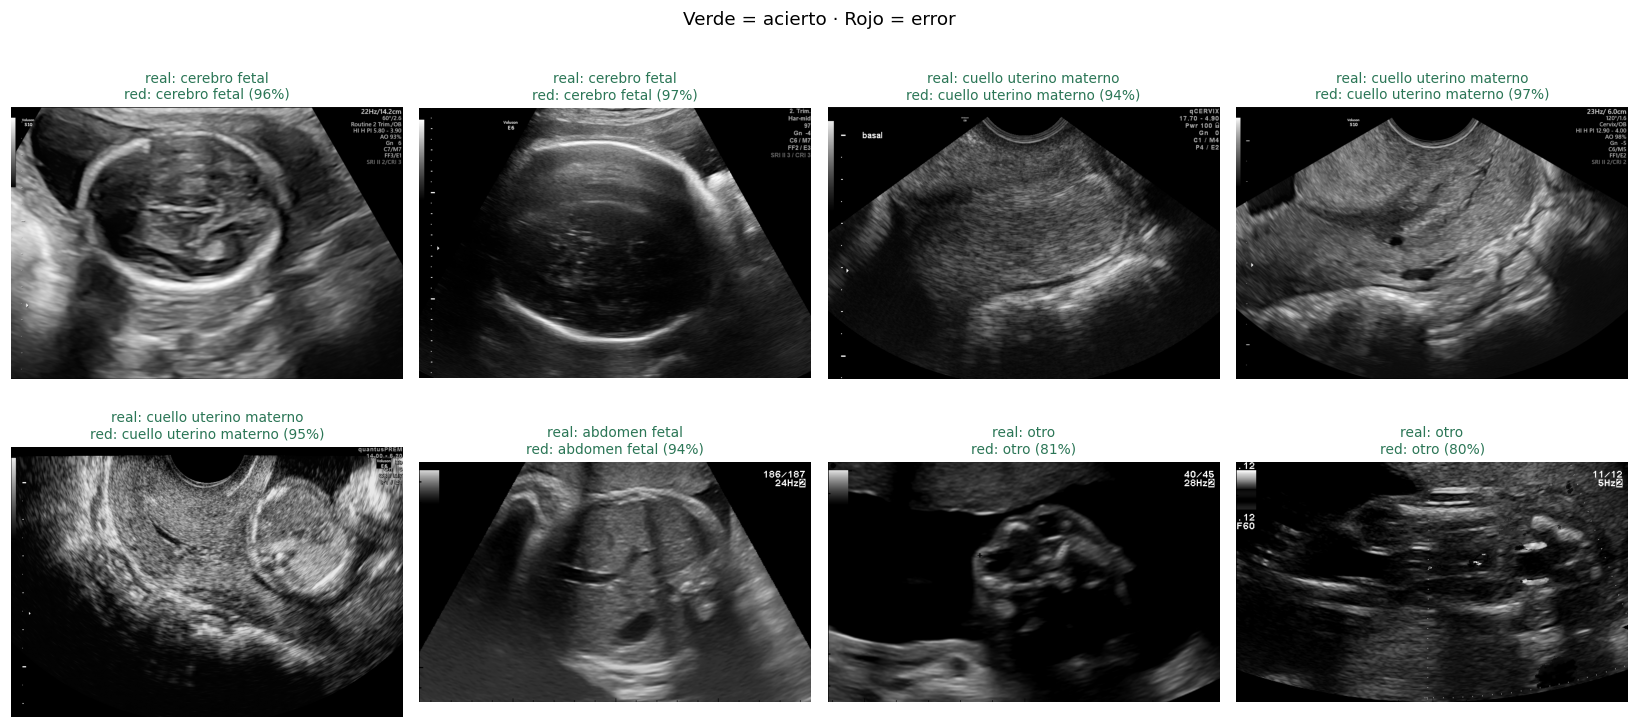

In [17]:
fig, ejes = plt.subplots(2, 4, figsize=(15, 7))
muestra = prueba_planos.sample(8, random_state=11)
for ax, (_, f) in zip(ejes.ravel(), muestra.iterrows()):
    ax.imshow(Image.open(f["ruta"]), cmap="gray"); ax.axis("off")
    ok = f["plano"] == f["plano_predicho"]
    confianza = f[f"prob_{f['plano_predicho']}"]
    ax.set_title(f"real: {f['plano']}\nred: {f['plano_predicho']} ({confianza:.0%})",
                 fontsize=9, color=VERDE if ok else ROJO)
fig.suptitle("Verde = acierto · Rojo = error", y=1.0)
plt.tight_layout()
plt.show()

---
## Paso 7: Evaluar el modelo

### 7.1 Red 1: R² y error en milímetros

| Métrica | Qué dice |
|---|---|
| **R²** | Qué parte de la variación de la medida explica la red. 1 = perfecto |
| **MAE** | Por cuántos milímetros se equivoca, en promedio |

In [18]:
# Paso 7: Evaluar el modelo
real, pred = prueba_hc["circunferencia_cefalica_mm"], prueba_hc["hc_predicha_mm"]
r2 = r2_score(real, pred)
mae = mean_absolute_error(real, pred)
mae_sem = mean_absolute_error(prueba_hc["semanas_real"], prueba_hc["semanas_predichas"])

print(f"Imágenes de prueba: {len(prueba_hc)} (de madres que la red no vio)")
print(f"R²                         = {r2:.4f}")
print(f"Error medio (MAE)          = {mae:.2f} mm")
print(f"Error mediano              = {prueba_hc['error_mm'].abs().median():.2f} mm")
print(f"Error en semanas (Hadlock) = {mae_sem:.2f} semanas de media")
print()
print(prueba_hc.assign(err=prueba_hc["error_mm"].abs())
      .groupby("trimestre")["err"].agg(["count", "mean", "median"]).round(2)
      .rename(columns={"count": "imágenes", "mean": "error medio mm", "median": "error mediano mm"}))

Imágenes de prueba: 146 (de madres que la red no vio)
R²                         = 0.9780
Error medio (MAE)          = 6.95 mm
Error mediano              = 5.43 mm
Error en semanas (Hadlock) = 0.62 semanas de media

           imágenes  error medio mm  error mediano mm
trimestre                                            
primero          19            7.29              5.61
segundo         105            6.17              5.19
tercero          22           10.40              7.38


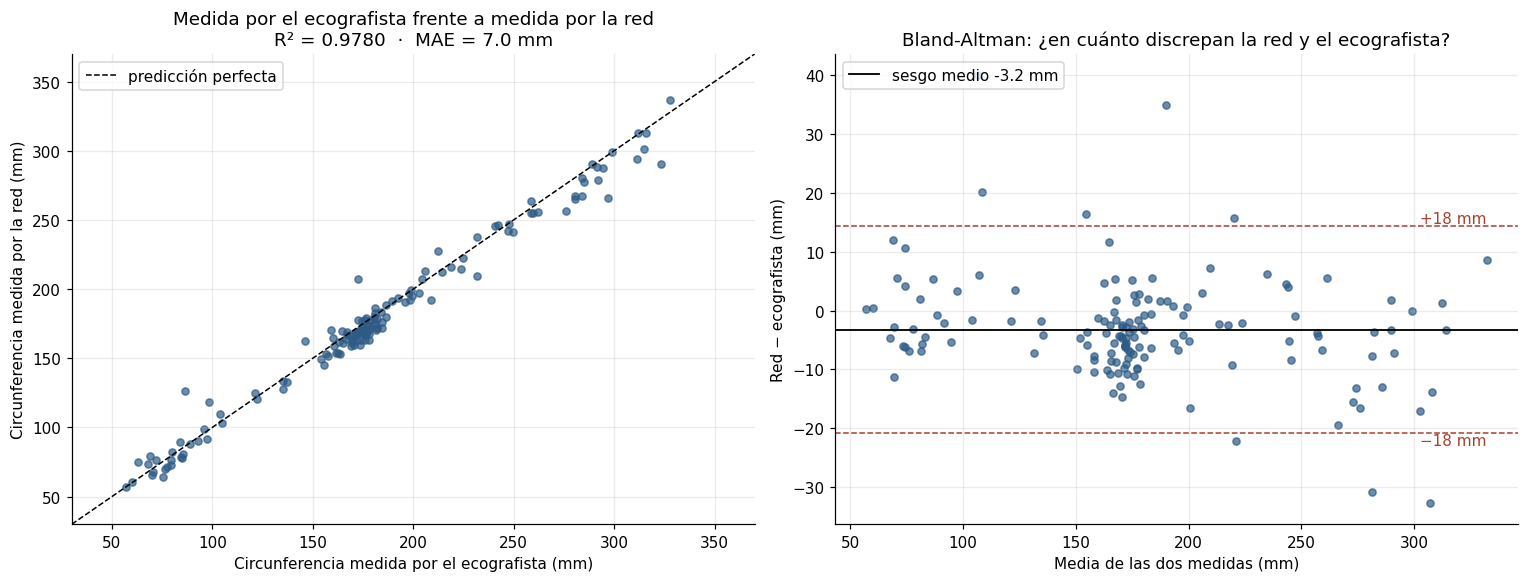

In [19]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.4))
a1.scatter(real, pred, s=22, alpha=0.7, color=AZUL)
lim = [30, 370]
a1.plot(lim, lim, "k--", lw=1, label="predicción perfecta")
a1.set_xlim(lim); a1.set_ylim(lim)
a1.set_title(f"Medida por el ecografista frente a medida por la red\nR² = {r2:.4f}  ·  MAE = {mae:.1f} mm")
a1.set_xlabel("Circunferencia medida por el ecografista (mm)")
a1.set_ylabel("Circunferencia medida por la red (mm)")
a1.legend()

media_par = (real + pred) / 2
dif = pred - real
sesgo, ds = dif.mean(), dif.std()
a2.scatter(media_par, dif, s=22, alpha=0.7, color=AZUL)
a2.axhline(sesgo, color="black", lw=1.2, label=f"sesgo medio {sesgo:+.1f} mm")
for lim_ in (sesgo - 1.96 * ds, sesgo + 1.96 * ds):
    a2.axhline(lim_, color=ROJO, ls="--", lw=1)
a2.text(media_par.max(), sesgo + 1.96 * ds, f" +{1.96 * ds:.0f} mm", color=ROJO, va="bottom", ha="right")
a2.text(media_par.max(), sesgo - 1.96 * ds, f" −{1.96 * ds:.0f} mm", color=ROJO, va="top", ha="right")
a2.set_title("Bland-Altman: ¿en cuánto discrepan la red y el ecografista?")
a2.set_xlabel("Media de las dos medidas (mm)")
a2.set_ylabel("Red − ecografista (mm)")
a2.legend(loc="upper left")
plt.tight_layout()
plt.show()

La gráfica de la derecha (**Bland-Altman**) es la forma estándar en medicina
de comparar dos maneras de medir lo mismo. Las líneas rojas encierran el 95%
de las diferencias: dicen **cuánto puede discrepar la red de un ecografista**
en una imagen concreta.

### 7.2 Red 2: curvas ROC de verdaderos positivos

Una curva por plano. Muestra cuántas imágenes de ese plano se reconocen
(**verdaderos positivos**, eje vertical) según cuántas falsas alarmas se
acepten (eje horizontal). Cuanto más pegada a la esquina de arriba a la
izquierda, mejor. El **AUC** es el área bajo la curva: 1 = perfecto, 0,5 = azar.

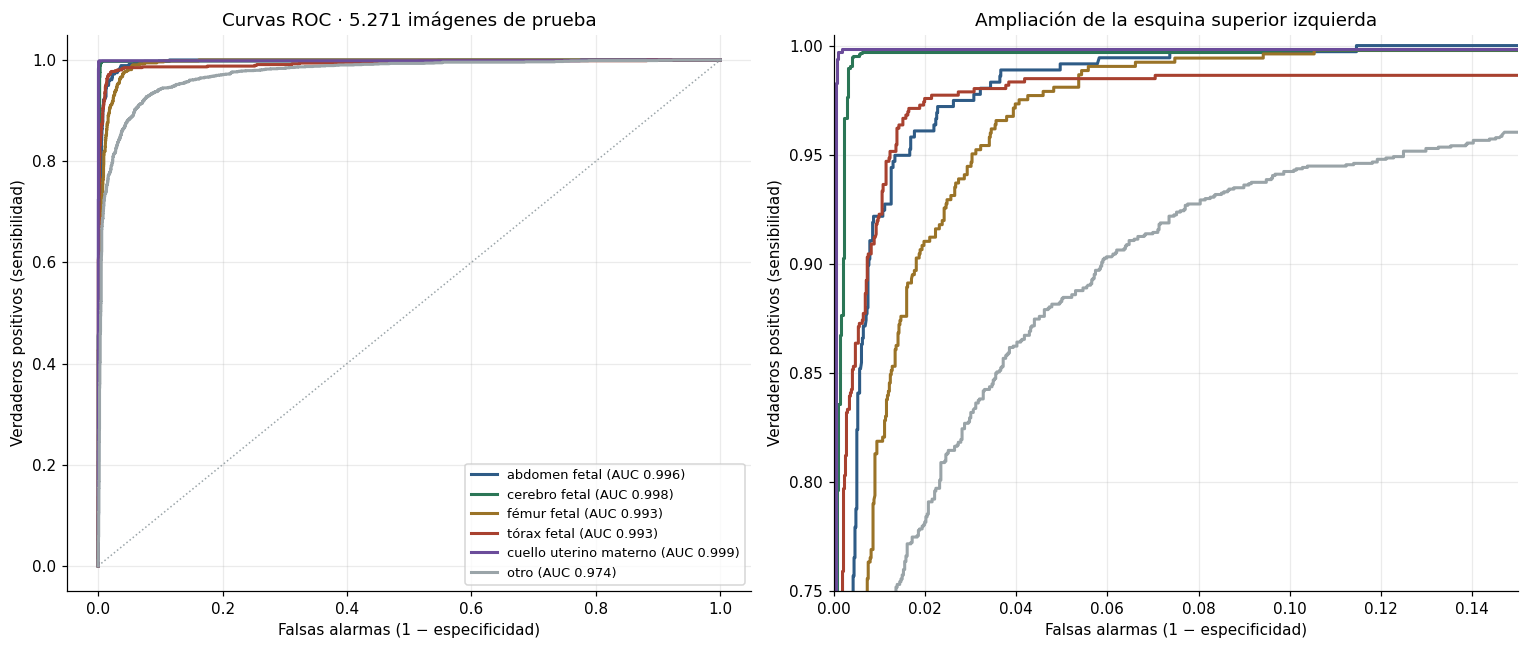

In [20]:
y_real = prueba_planos["plano"]
y_pred = prueba_planos["plano_predicho"]
colores_plano = [AZUL, VERDE, OCRE, ROJO, "#6b4c9a", GRIS]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 6))
aucs = {}
for plano, color in zip(cnn.PLANOS, colores_plano):
    verdad = (y_real == plano).astype(int)
    fpr, tpr, _ = roc_curve(verdad, prueba_planos[f"prob_{plano}"])
    aucs[plano] = roc_auc_score(verdad, prueba_planos[f"prob_{plano}"])
    for ax in (a1, a2):
        ax.plot(fpr, tpr, color=color, lw=2, label=f"{plano} (AUC {aucs[plano]:.3f})")
for ax in (a1, a2):
    ax.plot([0, 1], [0, 1], color=GRIS, ls=":", lw=1)
    ax.set_xlabel("Falsas alarmas (1 − especificidad)")
    ax.set_ylabel("Verdaderos positivos (sensibilidad)")
a1.set_title(f"Curvas ROC · {len(prueba_planos):,} imágenes de prueba".replace(",", "."))
a1.legend(loc="lower right", fontsize=8.5)
a2.set_xlim(0, 0.15); a2.set_ylim(0.75, 1.005)
a2.set_title("Ampliación de la esquina superior izquierda")
plt.tight_layout()
plt.show()

### 7.3 Red 2: matriz de confusión y verdaderos positivos por plano

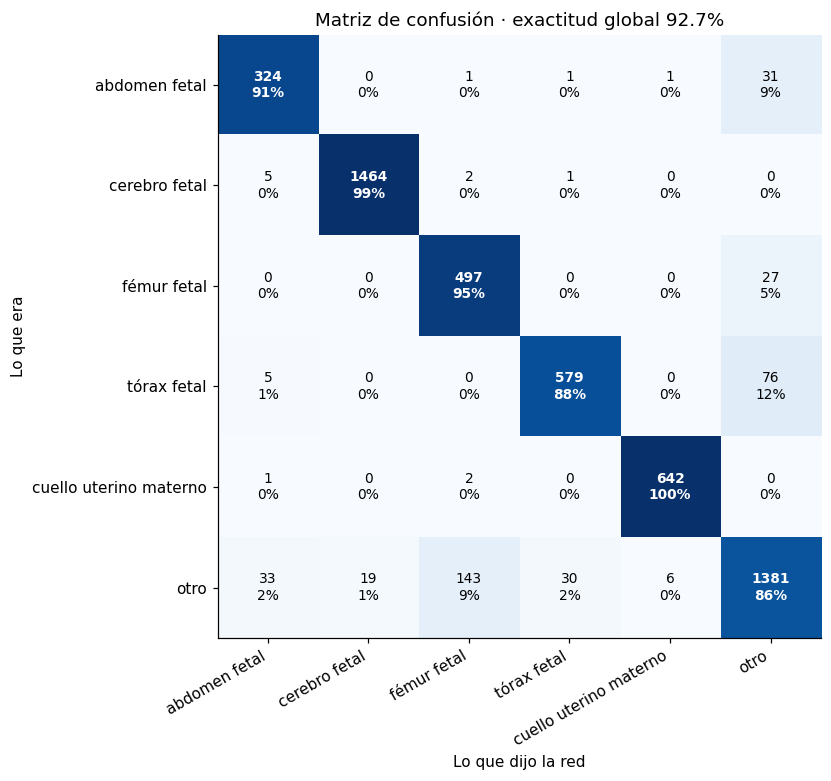

,imágenes de prueba,verdaderos positivos,se confundieron,sensibilidad,precisión,AUC
abdomen fetal,358,324,34,90.5%,88.0%,0.9956
cerebro fetal,1472,1464,8,99.5%,98.7%,0.9980
fémur fetal,524,497,27,94.8%,77.1%,0.9929
tórax fetal,660,579,81,87.7%,94.8%,0.9925
cuello uterino materno,645,642,3,99.5%,98.9%,0.9986
otro,1612,1381,231,85.7%,91.2%,0.9741


In [21]:
mc = confusion_matrix(y_real, y_pred, labels=cnn.PLANOS)
fig, ax = plt.subplots(figsize=(9, 7.2))
ax.imshow(mc / mc.sum(axis=1, keepdims=True), cmap="Blues")
ax.grid(False)
for i in range(len(cnn.PLANOS)):
    for j in range(len(cnn.PLANOS)):
        fila = mc[i].sum()
        ax.text(j, i, f"{mc[i, j]}\n{mc[i, j] / fila:.0%}", ha="center", va="center", fontsize=9,
                color="white" if mc[i, j] / fila > 0.5 else "black",
                fontweight="bold" if i == j else "normal")
ax.set_xticks(range(6), cnn.PLANOS, rotation=30, ha="right")
ax.set_yticks(range(6), cnn.PLANOS)
ax.set_xlabel("Lo que dijo la red")
ax.set_ylabel("Lo que era")
ax.set_title(f"Matriz de confusión · exactitud global {accuracy_score(y_real, y_pred):.1%}")
plt.tight_layout()
plt.show()

vp = pd.DataFrame({
    "imágenes de prueba": mc.sum(axis=1),
    "verdaderos positivos": np.diag(mc),
    "se confundieron": mc.sum(axis=1) - np.diag(mc),
    "sensibilidad": np.diag(mc) / mc.sum(axis=1),
    "precisión": np.diag(mc) / mc.sum(axis=0),
    "AUC": [aucs[p] for p in cnn.PLANOS],
}, index=cnn.PLANOS)
vp.style.format({"sensibilidad": "{:.1%}", "precisión": "{:.1%}", "AUC": "{:.4f}"})

La **diagonal** son los verdaderos positivos. Lo que queda fuera casi siempre
es **«otro»**: imágenes que no son ninguno de los cinco planos estándar y que a
veces se parecen a uno. Es el error más esperable y el menos grave: el sistema
diría «no reconozco el plano» y pediría otra imagen.

### 7.4 Resumen

In [22]:
print("RED 1 · CIRCUNFERENCIA CEFÁLICA (regresión, HC18)")
print(f"  R² = {r2:.4f}   ·   error medio {mae:.1f} mm   ·   {mae_sem:.2f} semanas de error en la edad")
print(f"  Evaluada en {len(prueba_hc)} imágenes de {prueba_hc['paciente'].nunique()} madres que no vio")
print()
print("RED 2 · PLANO ANATÓMICO (clasificación, FETAL_PLANES_DB)")
print(f"  Exactitud {accuracy_score(y_real, y_pred):.1%}   ·   AUC medio {np.mean(list(aucs.values())):.4f}")
print(f"  Verdaderos positivos: {int(np.diag(mc).sum()):,} de {int(mc.sum()):,} imágenes".replace(",", "."))
print(f"  Sensibilidad por plano: de {vp['sensibilidad'].min():.1%} a {vp['sensibilidad'].max():.1%}")
print(f"  Evaluada en la partición de prueba oficial: {prueba_planos['paciente'].nunique():,} madres".replace(",", "."))

RED 1 · CIRCUNFERENCIA CEFÁLICA (regresión, HC18)
  R² = 0.9780   ·   error medio 7.0 mm   ·   0.62 semanas de error en la edad
  Evaluada en 146 imágenes de 117 madres que no vio

RED 2 · PLANO ANATÓMICO (clasificación, FETAL_PLANES_DB)
  Exactitud 92.7%   ·   AUC medio 0.9920
  Verdaderos positivos: 4.887 de 5.271 imágenes
  Sensibilidad por plano: de 85.7% a 99.5%
  Evaluada en la partición de prueba oficial: 896 madres


### Comparado con lo publicado

| | Este trabajo | Publicación original |
|---|---|---|
| Red 2, exactitud en los 6 planos | ver arriba | ~93% (Burgos-Artizzu et al., *Sci Rep* 2020) |
| Red 1, error en la circunferencia | ver arriba | ~2 mm con segmentación de la elipse (reto HC18) |

La red 2 queda al nivel de la publicación. La red 1 **mide directamente**, sin
dibujar la elipse de la cabeza, y por eso es más simple pero comete más error
que los métodos que ganaron el reto. Dibujar la elipse sería el siguiente paso
para bajar a unos 2 mm.

---
## Cuándo y cómo implementarlo

### De qué se trata

Dos ayudas para la ecografía:

1. **Medir la cabeza sola.** La red mide la circunferencia cefálica y, con
   Hadlock, da las semanas de embarazo. Sirve para comprobar la medida del
   ecografista o proponerla.
2. **Reconocer el plano.** Antes de medir, comprueba que la imagen sea de
   verdad una cabeza (o un abdomen, o un fémur). Evita medir el plano
   equivocado.

No sustituye al ecografista: **propone y comprueba**.

### En qué módulo entra

| Pieza | Dónde |
|---|---|
| Este notebook, las imágenes y el catálogo | `historial/datos_ecografia_reales/` |
| Las redes entrenadas | `datos_ecografia_reales/modelos/` y copiadas a `Backend/Microservicio_IA/trained_models/` |
| El servicio que las usa | Microservicio de IA (`Backend/Microservicio_IA/`): `POST /api/biometria/circunferencia-cefalica` y `POST /api/plano-anatomico` |
| La fórmula de Hadlock | `Backend/ecografias/peso_fetal.py` |
| Dónde se vería | Ficha de la ecografía → pestaña **Biometría Fetal** |

Además **sustituye a la «cabeza de biometría» de la red principal**, que estaba
declarada en la propuesta del proyecto pero entrenada con objetivos simulados y
sin validar.

### Cuándo implementarlo

1. **Ya se puede usar como ayuda en pruebas**: está entrenada y evaluada con
   datos reales publicados, con resultados al nivel de la literatura.
2. **Antes de usarla con pacientes, validarla con ecografías de la clínica.**
   Estas imágenes son de hospitales de los Países Bajos y de Barcelona, con sus
   ecógrafos. Hay que comprobar con unas 100 ecografías bolivianas, medidas por
   un ecografista, que el error sigue siendo parecido.
3. **Necesita el tamaño del píxel.** Sin él no hay milímetros. Los archivos
   DICOM del ecógrafo lo traen (`PixelSpacing`); una captura de pantalla, no.

### Cómo implementarlo

1. El microservicio carga las dos redes al arrancar.
2. Al subir una ecografía, primero la red 2 dice qué plano es.
3. Si es cabeza, la red 1 mide la circunferencia y Hadlock da las semanas.
4. La pantalla muestra la medida de la red **al lado de la del ecografista**,
   y avisa si discrepan más de lo que marca el Bland-Altman del paso 7.1.